In [ ]:
## 02 - Data Quality Assessment

In [ ]:
### Business Objective

# The objective of this notebook is to assess the
# quality and consistency of the credit risk dataset.

In [16]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [17]:

# 1. Definicja ścieżki
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw"
DATA_FILE = RAW_PATH / "credit_card_default.csv"

# 2. Wczytanie danych
df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully
Shape: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [18]:
data_profile = pd.DataFrame({
    "column": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "missing_values": df.isna().sum().values,
    "missing_pct": (
        df.isna().mean().values * 100
    ).round(2),
    "unique_values": df.nunique().values
})

display(
    data_profile.sort_values(
        "missing_pct",
        ascending=False
    )
)

,column,data_type,missing_values,missing_pct,unique_values
0,LIMIT_BAL,int64,0,0.0,81
1,SEX,int64,0,0.0,2
2,EDUCATION,int64,0,0.0,7
3,MARRIAGE,int64,0,0.0,4
4,AGE,int64,0,0.0,56
5,PAY_0,int64,0,0.0,11
6,PAY_2,int64,0,0.0,11
7,PAY_3,int64,0,0.0,11
8,PAY_4,int64,0,0.0,11
9,PAY_5,int64,0,0.0,10


In [19]:
OUTPUT_PATH = PROJECT_ROOT / "data" / "outputs"

data_profile.to_csv(
    OUTPUT_PATH / "data_profile.csv",
    index=False
)

In [20]:
# checking for empty values in the dataset

missing = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_pct = (
    df.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct
})

display(missing_report)

,missing_count,missing_pct
LIMIT_BAL,0,0.0
SEX,0,0.0
EDUCATION,0,0.0
MARRIAGE,0,0.0
AGE,0,0.0
PAY_0,0,0.0
PAY_2,0,0.0
PAY_3,0,0.0
PAY_4,0,0.0
PAY_5,0,0.0


In [21]:
missing_plot = missing_report[
    missing_report["missing_count"] > 0
]

if len(missing_plot) > 0:
    plt.figure(figsize=(12, 5))

    sns.barplot(
        data=missing_plot.reset_index(),
        x="index",
        y="missing_pct"
    )

    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Values (%)")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected.")

No missing values detected.


In [22]:
# checking for duplicates

duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

if "ID" in df.columns:
    print(
        "Duplicate IDs:",
        df["ID"].duplicated().sum()
    )

Exact duplicate rows: 35


In [ ]:
# checking target

In [23]:
TARGET = "DEFAULT"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column {TARGET} not found."
    )

print("Target distribution:")
display(df[TARGET].value_counts(dropna=False))

print("\nTarget percentage:")
display(
    df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target distribution:


DEFAULT
0    23364
1     6636
Name: count, dtype: int64


Target percentage:


DEFAULT
0    77.88
1    22.12
Name: proportion, dtype: float64

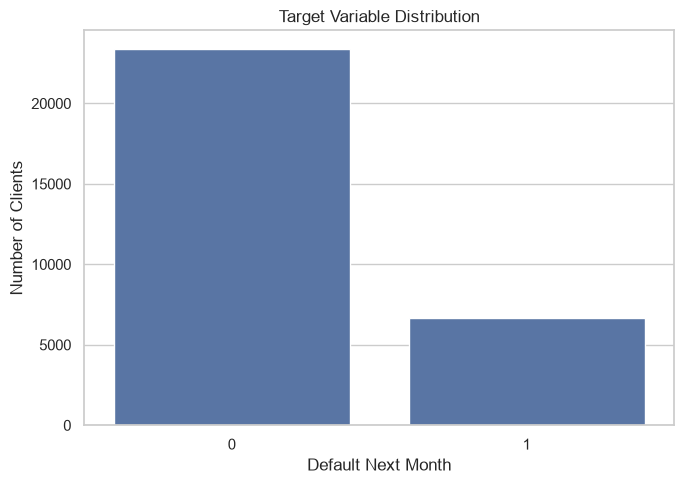

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=TARGET
)

plt.title("Target Variable Distribution")
plt.xlabel("Default Next Month")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()

In [25]:
valid_target_values = {0, 1}

invalid_target = df[
    ~df[TARGET].isin(valid_target_values)
]

print(
    "Invalid target records:",
    len(invalid_target)
)

Invalid target records: 0


In [ ]:
# stats of df 

In [26]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

display(
    df[numeric_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


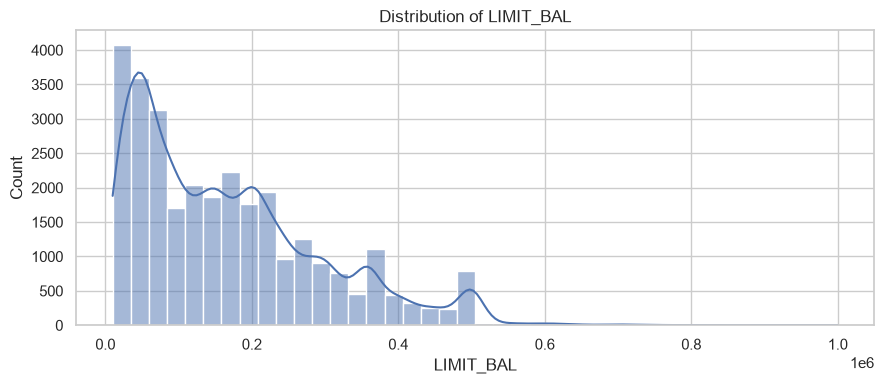

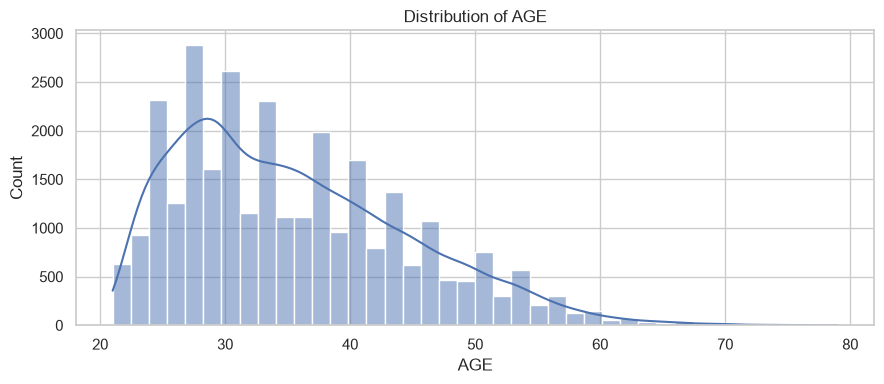

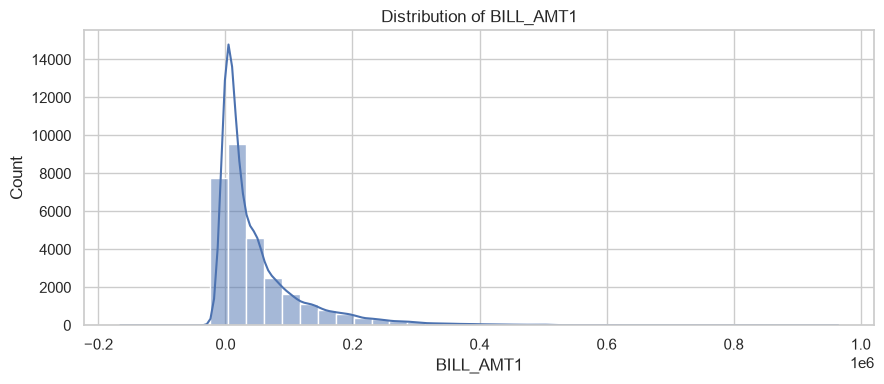

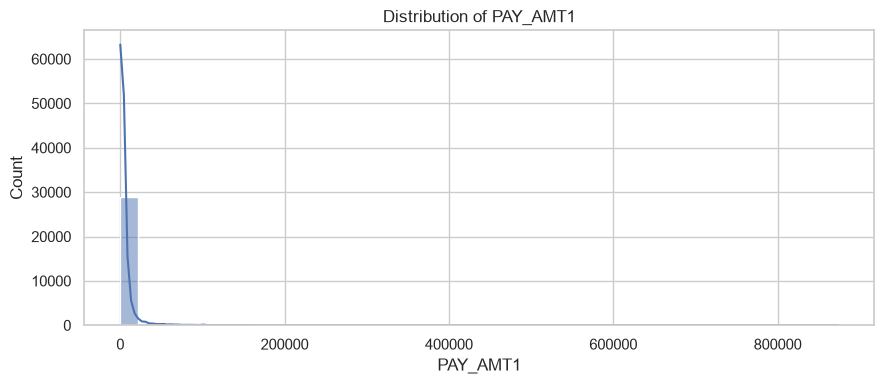

In [29]:
columns_to_plot = [
    col for col in [
        "LIMIT_BAL",
        "AGE",
        "BILL_AMT1",
        "PAY_AMT1"
    ]
    if col in df.columns
]

for col in columns_to_plot:

    plt.figure(figsize=(9, 4))

    sns.histplot(
        data=df,
        x=col,
        bins=40,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

In [30]:
quality_report = pd.DataFrame({
    "metric": [
        "Number of records",
        "Number of columns",
        "Missing values",
        "Duplicate rows",
        "Invalid target values"
    ],
    "value": [
        len(df),
        len(df.columns),
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(
            (~df[TARGET].isin([0, 1])).sum()
        )
    ]
})

display(quality_report)

,metric,value
0,Number of records,30000
1,Number of columns,24
2,Missing values,0
3,Duplicate rows,35
4,Invalid target values,0


In [31]:
quality_report.to_csv(
    OUTPUT_PATH / "data_quality_report.csv",
    index=False
)